# Research Paper Answer Bot

A retrieval-augmented generation (RAG) system over 11 seminal Generative AI papers. A question in plain language gets an answer written only from the papers, with the top 3 supporting passages cited by paper title and page number.

| Step | Section | Status |
|---|---|---|
| 1 | Setup and configuration | done |
| 2 | Data loading and inspection | done |
| 3 | Chunking experiments | done |
| 4 | Embedding model comparison | done |
| 5 | Vector database build | done |
| 6 | Retrieval strategy comparison | done |
| 7 | RAG pipeline construction | next milestone |
| 8 | Evaluation and failure analysis | |
| 9 | Stretch goals | |
| 10 | Final demo | |
| 11 | Experiment summary and conclusions | |

All pipeline logic lives in the `rpab` package under `backend/`; this notebook imports it, runs each step, and records the observations and decisions.

## 1. Setup and configuration

**Intent.** Make every run repeatable: one configuration object, fixed random seeds, and a switch that decides whether slow experiments are recomputed or loaded from `artifacts/`.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the notebook runs from backend/notebooks
logging.getLogger("pypdf").setLevel(logging.ERROR)  # hide pypdf's per-page font warnings

import matplotlib.pyplot as plt
import pandas as pd

from rpab.config import CONFIG
from rpab.utils import set_seed

set_seed(CONFIG.seed)

# True recomputes slow experiments (about 3 minutes for the loader comparison);
# False loads their saved results from artifacts/ when they exist.
RUN_EXPERIMENTS = False

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

# Chart style. Single-series charts use one hue; comparisons use a fixed
# categorical order that passes colour-vision-deficiency checks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c9c8c3", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False,
})

pd.DataFrame({
    "setting": ["seed", "pdf_loader", "chunking", "embedding (open)", "embedding (commercial)",
                "retrieval_k / final_k", "reranker", "llm", "llm context (num_ctx)"],
    "value": [CONFIG.seed, CONFIG.pdf_loader,
              f"{CONFIG.chunking_strategy} {CONFIG.chunk_size}/{CONFIG.chunk_overlap}",
              CONFIG.embedding_models["open"], CONFIG.embedding_models["commercial"],
              f"{CONFIG.retrieval_k} / {CONFIG.final_k}", CONFIG.reranker_model,
              CONFIG.llm_model, CONFIG.llm_num_ctx],
}).set_index("setting")

,value
setting,
seed,42
pdf_loader,pypdf
chunking,fixed 512/0
embedding (open),BAAI/bge-m3
embedding (commercial),models/gemini-embedding-001
retrieval_k / final_k,20 / 3
reranker,BAAI/bge-reranker-v2-m3
llm,llama3.1:latest
llm context (num_ctx),8192


**Decision.** All settings live in `rpab/config.py`; the API key is read from `backend/.env.local` and never printed. Seeds are fixed at 42 for Python, NumPy and PyTorch. The values above are starting points; the experiments in later sections tune them.

## 2. Data loading and inspection

**Intent.** Turn each PDF into one LangChain `Document` per page, carrying the metadata a citation needs (`paper_id`, `paper_title`, `source_file`, 1-based `page`). Then measure extraction quality, clean the text, and explore the corpus before any chunking decision.

Loading **page by page** is deliberate: the bot must cite page numbers, so page boundaries are kept from the start and chunks will never cross them.

### 2.1 Dataset

11 papers, identified by the arXiv id in each file name and matched to a hand-written catalog (`data/papers.json`) that holds the exact titles. A file with no catalog match stops ingestion, because a guessed title would produce a wrong citation.

In [2]:
from rpab.loaders import load_corpus, write_manifest

raw_pages, manifest = load_corpus(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.pdf_loader)
write_manifest(manifest, CONFIG.paths.manifest)

papers = pd.DataFrame(manifest).set_index("paper_id")
papers["file_hash"] = papers["file_hash"].str[:12] + "…"
print(f"{len(papers)} papers, {papers['num_pages'].sum()} pages")
papers[["paper_title", "year", "arxiv_id", "num_pages", "file_hash"]].sort_values("year")

11 papers, 411 pages


,paper_title,year,arxiv_id,num_pages,file_hash
paper_id,,,,,
attention,Attention Is All You Need,2017,1706.03762,15,bdfaa68d8984…
bert,BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding,2018,1810.04805,16,5692a5514787…
dpr,Dense Passage Retrieval for Open-Domain Question Answering,2020,2004.04906,13,3e67fc1a9977…
gpt3,Language Models are Few-Shot Learners,2020,2005.14165,75,97fd272f1fdf…
rag,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,2005.11401,19,23e3249e9a1e…
lora,LoRA: Low-Rank Adaptation of Large Language Models,2021,2106.09685,26,e9a0d3128767…
instructgpt,Training language models to follow instructions with human feedback,2022,2203.02155,68,c1984bb50a5b…
cot,Chain-of-Thought Prompting Elicits Reasoning in Large Language Models,2022,2201.11903,43,7d9f878c23b4…
react,ReAct: Synergizing Reasoning and Acting in Language Models,2022,2210.03629,33,f285b0971ae4…


### 2.2 Loader comparison: `PyPDFLoader` vs `PDFPlumberLoader`

Both LangChain loaders run on all 11 papers. Signals recorded per paper:

- **seconds**: extraction time
- **total_chars**: characters extracted
- **cid_glyphs**: `(cid:NN)` tokens, i.e. glyphs the loader could not map to a character (pure noise in the index)
- **ligatures**: typographic ligatures such as "ﬁ" left in the text (fixable in cleaning)
- **hyphen_breaks**: words split across a line break (fixable in cleaning)

In [3]:
from rpab.loaders import compare_loaders

if RUN_EXPERIMENTS or not CONFIG.paths.loader_comparison.exists():
    loader_cmp = compare_loaders(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.empty_page_chars)
    loader_cmp.to_csv(CONFIG.paths.loader_comparison, index=False)
else:
    loader_cmp = pd.read_csv(CONFIG.paths.loader_comparison)

totals = loader_cmp.groupby("loader")[["seconds", "total_chars", "empty_pages", "cid_glyphs", "ligatures", "hyphen_breaks"]].sum()
totals

,seconds,total_chars,empty_pages,cid_glyphs,ligatures,hyphen_breaks
loader,,,,,,
pdfplumber,187.74,1248793,0,7286,0,787
pypdf,61.06,1323602,0,0,1760,969


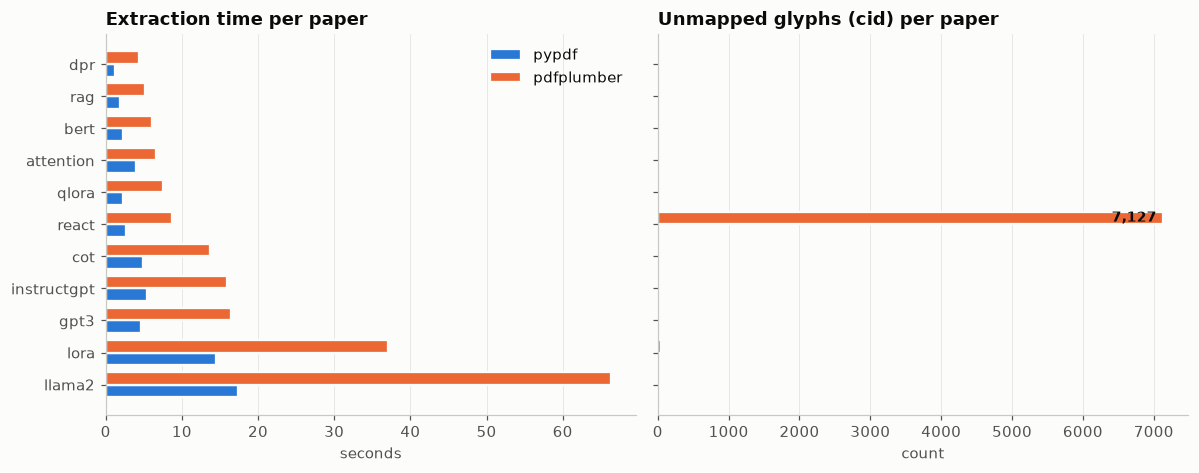

In [4]:
def grouped_barh(ax, table, columns, title, xlabel):
    # Horizontal grouped bars, one colour per column in fixed order, a surface-coloured gap between bars.
    rows = range(len(table))
    height = 0.8 / len(columns)
    for k, col in enumerate(columns):
        ax.barh([r + (k - (len(columns) - 1) / 2) * height for r in rows], table[col], height=height,
                color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=col)
    ax.set_yticks(list(rows), table.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)

wide = loader_cmp.pivot(index="paper_id", columns="loader")
order = wide[("seconds", "pdfplumber")].sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
grouped_barh(ax1, wide["seconds"].loc[order], ["pypdf", "pdfplumber"], "Extraction time per paper", "seconds")
grouped_barh(ax2, wide["cid_glyphs"].loc[order], ["pypdf", "pdfplumber"], "Unmapped glyphs (cid) per paper", "count")
react_cid = wide.loc["react", ("cid_glyphs", "pdfplumber")]
ax2.annotate(f"{react_cid:,}", xy=(react_cid, list(order).index("react") + 0.2), xytext=(-4, 0),
             textcoords="offset points", ha="right", va="center", color=INK, fontsize=9, fontweight="bold")
ax1.legend(loc="upper right")
fig.tight_layout()

A sample makes the difference concrete: the ReAct page where `pdfplumber` produced the most unmapped glyphs, read by both loaders.

In [5]:
from rpab.loaders import discover_pdfs, identify, load_catalog, load_pdf, page_stats

catalog = load_catalog(CONFIG.paths.catalog)
react_pdf = next(p for p in discover_pdfs(CONFIG.paths.pdf_dir) if "2210.03629" in p.name)
react_meta = identify(react_pdf, catalog)
plumber_pages = load_pdf(react_pdf, react_meta, "pdfplumber")
worst = page_stats(plumber_pages, CONFIG.empty_page_chars).sort_values("cid_glyphs").iloc[-1]
page_no = int(worst["page"])
pypdf_page = load_pdf(react_pdf, react_meta, "pypdf")[page_no - 1]

print(f"ReAct page {page_no}: {int(worst['cid_glyphs'])} unmapped glyphs with pdfplumber\n")
print("pdfplumber:\n" + plumber_pages[page_no - 1].page_content[:320] + "\n")
print("pypdf:\n" + pypdf_page.page_content[:320])

ReAct page 2: 3112 unmapped glyphs with pdfplumber

pdfplumber:
PublishedasaconferencepaperatICLR2023
(cid:11)(cid:20)(cid:12)(cid:3)(cid:43)(cid:82)(cid:87)(cid:86)(cid:83)(cid:82)(cid:87)(cid:3)(cid:52)(cid:36) (cid:11)(cid:20)(cid:71)(cid:12)(cid:3)(cid:53)(cid:72)(cid:36)(cid:70)(cid:87)(cid:3)(cid:11)(cid:53)(cid:72)(cid:68)(cid:86)(cid:82)(cid:81)(cid:3)(cid:14)(cid:3)(cid:36

pypdf:
Published as a conference paper at ICLR 2023
$FW7KLQN>)LUVW,QHHGWRILQGDSHSSHUVKDNHUPRUH
OLNHO\WRDSSHDULQFDELQHWVFRXQWHUWRSV@
$FW*RWRFDELQHW
2EV2QWKHFDELQHW\RXVHHDYDVH
+HUHWKHDJHQWJRWRFDELQHWWKHQFDELQHWWKHQFRXQWHUWRSDQG
$FW*RW


**Observations.**

- `pypdf` is about 3× faster: 61 s against 188 s for all 411 pages. Llama 2 alone takes 66 s with `pdfplumber`.
- `pdfplumber` leaves 7,286 unmapped `(cid:NN)` glyphs, 7,127 of them in ReAct, where figure text uses an embedded font with a custom encoding. That text is lost for good.
- `pypdf` extracts the same ReAct text as letters shifted by 29 code points (sample above). It looks like noise, but it is recoverable in cleaning. None of the metrics above counted it, which is why the sample check matters.
- `pypdf` leaves 1,760 ligatures and 969 line-break hyphens; both are mechanical to fix.
- Two-column papers (BERT, DPR) come out in the right column order; checked on DPR page 2.

**Decision.** Use `PyPDFLoader` (`CONFIG.pdf_loader = "pypdf"`): faster, more text, and its defects can all be repaired, while `pdfplumber`'s cannot.

### 2.3 Cleaning

Rules in `rpab/cleaning.py`, applied in order to every page:

1. Replace ligatures with plain letters ("ﬁ" → "fi").
2. Decode shifted-font lines. Some ReAct figures embed a font whose character codes sit 29 below the real letters, so pypdf extracts "Think" as "7KLQN" and the space as the control character U+0003. A line where U+0003 outnumbers real spaces is shifted back; any other stray control character (a symbol glyph such as a check mark) is deleted.
3. Remove the arXiv side stamp (e.g. `arXiv:1706.03762v7 [cs.CL] 2 Aug 2023`).
4. Drop repeated header/footer lines: a line at a page's top or bottom edge whose shape (digits → `#`) appears at the edges of at least half the paper's pages. This removes page numbers and running heads.
5. Re-join words hyphenated across a line break ("ef-⏎ficient" → "efficient").
6. Normalise whitespace.

The raw text stays next to the cleaned text in `artifacts/pages.parquet`, so any cleaning decision can be audited later.

In [6]:
from rpab.cleaning import clean_documents

pages, page_log = clean_documents(raw_pages, CONFIG.repeated_line_share)
page_table = page_log.merge(page_stats(pages, CONFIG.empty_page_chars), on=["paper_id", "page"])
CONFIG.paths.artifacts_dir.mkdir(parents=True, exist_ok=True)
page_table.to_parquet(CONFIG.paths.pages, index=False)

rule_cols = ["ligatures_fixed", "shifted_lines_decoded", "control_chars_removed", "arxiv_stamps_removed",
             "edge_lines_removed", "hyphens_joined"]
cleaning = page_log.groupby("paper_id")[rule_cols].sum()
cleaning.loc["total"] = cleaning.sum()
cleaning

,ligatures_fixed,shifted_lines_decoded,control_chars_removed,arxiv_stamps_removed,edge_lines_removed,hyphens_joined
paper_id,,,,,,
attention,0,0,0,1,14,16
bert,157,0,0,1,0,332
cot,288,0,17,1,47,48
dpr,92,0,9,1,0,232
gpt3,444,0,0,1,74,23
instructgpt,352,0,0,1,77,43
llama2,0,0,1,1,76,66
lora,210,0,0,1,26,85
qlora,0,0,8,1,25,47


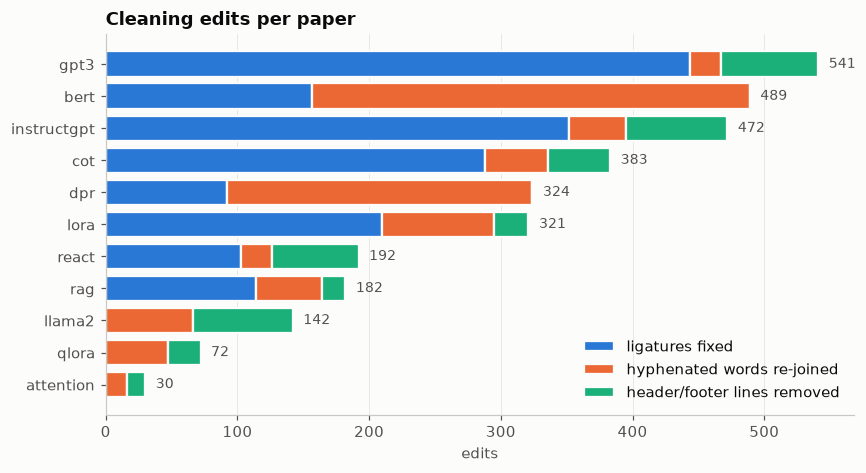

In [7]:
impact = page_log.groupby("paper_id")[["ligatures_fixed", "hyphens_joined", "edge_lines_removed"]].sum()
impact = impact.loc[impact.sum(axis=1).sort_values().index]
labels = {"ligatures_fixed": "ligatures fixed", "hyphens_joined": "hyphenated words re-joined",
          "edge_lines_removed": "header/footer lines removed"}

fig, ax = plt.subplots(figsize=(8, 4.4))
left = pd.Series(0, index=impact.index)
for k, col in enumerate(labels):
    ax.barh(impact.index, impact[col], left=left, color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=labels[col])
    left = left + impact[col]
for y, total in enumerate(left):
    ax.text(total + 8, y, f"{int(total)}", va="center", color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_title("Cleaning edits per paper")
ax.set_xlabel("edits")
ax.legend(loc="lower right")
fig.tight_layout()

In [8]:
example = page_log[(page_log["paper_id"] == "dpr") & (page_log["page"] == 1)].iloc[0]
print("RAW:\n" + example["raw_text"][:430] + "\n")
print("CLEAN:\n" + example["clean_text"][:430])

RAW:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on ef-
ﬁcient passage retrieval to select c

CLEAN:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on efficient passage retrieval to select ca


**Observations.**

- 1,760 ligatures fixed and 965 hyphenated words re-joined. BERT and DPR, both two-column with narrow lines, account for most re-joins.
- 423 header/footer lines removed: page numbers in nine papers plus ReAct's running head. BERT and DPR have no repeated edge lines, so nothing was removed there.
- 198 ReAct figure lines decoded from the shifted font; the agent trajectories in its Figure 1 now read "Act 1: Think[First I need to find a pepper shaker…". 64 stray symbol characters removed in five papers.
- The first version of rule 2 shifted any line containing a control character and corrupted 30 normal lines in CoT, DPR, QLoRA and Llama 2, where a single check-mark glyph triggered it. Requiring U+0003 to outnumber real spaces fixed that; the affected lines were checked one by one.
- Known limits: a shifted line holding one word has no space to detect, so two ReAct figure labels stay garbled ("VRIWZDUH" is "software"). Footnote marks (∗ † ‡) and split accents ("O˘guz") remain. Neither matters for retrieval.

**Decision.** Keep all six rules. The raw text stays in `artifacts/pages.parquet` beside the cleaned text.

### 2.4 Quality report

In [9]:
from rpab.loaders import quality_report

stats = page_stats(pages, CONFIG.empty_page_chars)
print(f"Empty pages (OCR candidates): {int(stats['is_empty'].sum())} of {len(stats)}")
quality_report(stats)

Empty pages (OCR candidates): 0 of 411


,pages,empty_pages,total_chars,mean_chars_per_page,min_chars_per_page,ligatures,cid_glyphs,hyphen_breaks,non_ascii_share
paper_id,,,,,,,,,
llama2,77,0,260023,3376.922,156,0,0,0,0.003
gpt3,75,0,236810,3157.467,100,0,0,0,0.004
instructgpt,68,0,181751,2672.809,348,0,0,0,0.003
cot,43,0,135506,3151.302,634,0,0,0,0.003
react,33,0,108365,3283.788,597,0,0,0,0.002
qlora,26,0,87637,3370.654,383,0,0,0,0.002
lora,26,0,82360,3167.692,1771,0,0,0,0.006
rag,19,0,68962,3629.579,1129,0,0,0,0.003
bert,16,0,63502,3968.875,2324,0,0,0,0.002


**Observations.** 0 of 411 pages are empty, and no ligatures, unmapped glyphs or line-break hyphens remain after cleaning, so every PDF has a usable text layer. The shortest pages (100 to 400 characters) are figure or table pages, not extraction failures.

**Decision.** OCR is not needed for this corpus. The empty-page count stays in the ingestion report, so a scanned PDF added later would be flagged.

### 2.5 Exploring the corpus

Corpus: 357,295 tokens


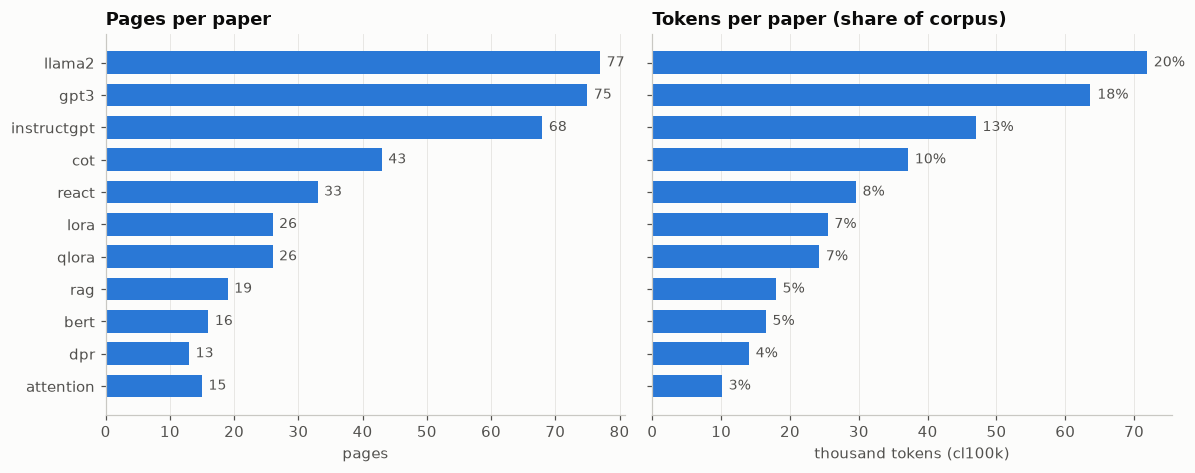

In [10]:
from rpab.eda import back_matter_split, count_tokens

page_table["tokens"] = count_tokens(page_table["clean_text"])
per_paper = page_table.groupby("paper_id").agg(pages=("page", "count"), tokens=("tokens", "sum"))
per_paper["token_share"] = per_paper["tokens"] / per_paper["tokens"].sum()
per_paper = per_paper.sort_values("tokens")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ax1.barh(per_paper.index, per_paper["pages"], color=SERIES[0], height=0.7)
for y, v in enumerate(per_paper["pages"]):
    ax1.text(v + 1, y, str(v), va="center", color=INK_2, fontsize=9)
ax1.set_title("Pages per paper")
ax1.set_xlabel("pages")
ax2.barh(per_paper.index, per_paper["tokens"] / 1000, color=SERIES[0], height=0.7)
for y, (v, s) in enumerate(zip(per_paper["tokens"], per_paper["token_share"])):
    ax2.text(v / 1000 + 1, y, f"{s:.0%}", va="center", color=INK_2, fontsize=9)
ax2.set_title("Tokens per paper (share of corpus)")
ax2.set_xlabel("thousand tokens (cl100k)")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
print(f"Corpus: {per_paper['tokens'].sum():,} tokens")

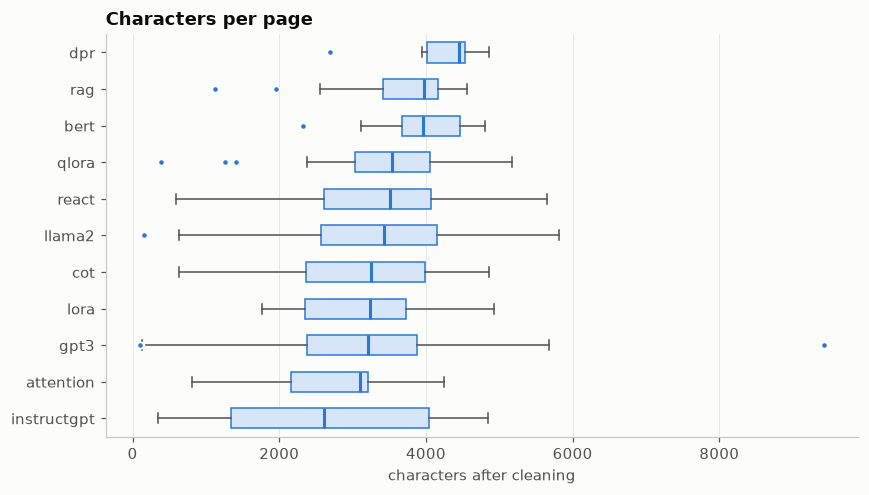

In [11]:
order = page_table.groupby("paper_id")["n_chars"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.boxplot([page_table.loc[page_table["paper_id"] == p, "n_chars"] for p in order], orientation="horizontal",
           tick_labels=list(order), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#d6e6f8", edgecolor=SERIES[0]), medianprops=dict(color=SERIES[0], linewidth=2),
           whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2),
           flierprops=dict(marker="o", markersize=4, markerfacecolor=SERIES[0], markeredgecolor=SURFACE))
ax.grid(axis="y", visible=False)
ax.set_title("Characters per page")
ax.set_xlabel("characters after cleaning")
fig.tight_layout()

,references_page,body_pages,back_matter_pages,total_pages
paper_id,,,,
dpr,9,8,5,13
attention,10,9,6,15
bert,10,9,7,16
rag,10,9,10,19
qlora,17,16,10,26
lora,13,12,14,26
react,10,9,24,33
cot,10,9,34,43
instructgpt,21,20,48,68


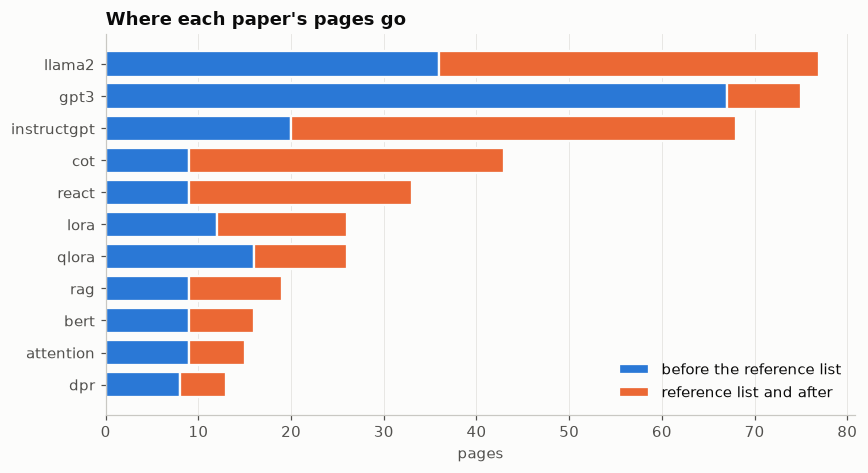

In [12]:
split = back_matter_split(page_table).sort_values("total_pages")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(split.index, split["body_pages"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="before the reference list")
ax.barh(split.index, split["back_matter_pages"], left=split["body_pages"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="reference list and after")
ax.grid(axis="y", visible=False)
ax.set_title("Where each paper's pages go")
ax.set_xlabel("pages")
ax.legend(loc="lower right")
fig.tight_layout()
split

**Observations.**

- The corpus is 411 pages and about 361k tokens. Three long papers hold just over half of it: Llama 2 (20%), GPT-3 (18%) and InstructGPT (13%). Attention Is All You Need is only 3%.
- Pages hold a median of 3,404 characters (middle half: 2,409 to 4,079). An 800-character chunk is about a quarter of a page, so most pages yield 4 to 5 chunks.
- In six papers more than half the pages come after the reference list starts: CoT 34 of 43, InstructGPT 48 of 68, ReAct 24 of 33, Llama 2 41 of 77, LoRA 14 of 26, RAG 10 of 19. GPT-3 is the exception because its appendices come before its references.

**Implications for the next steps.**

- Long papers will contribute the most chunks and so get more chances to appear in the top results. The evaluation questions must cover the short papers too, and retrieval results will be checked per paper.
- Appendices hold real content (extra experiments, prompts, model details) and stay in the index. Reference lists are mostly author names and venues; whether removing them improves retrieval will be tested as a chunking variant in section 3.
- Chunks must not cross page boundaries, so chunk size has to sit well below the typical page length. The 500, 800 and 1,200-character variants all do.

## 3. Chunking experiments

**Intent.** Pick the chunking that puts the passage holding the answer in the top 3. Every variant splits one page at a time, so a chunk never crosses a page boundary and its page number is exact; chunks under 100 characters (stray figure labels) are dropped. Each chunk gets a deterministic id, `{paper_id}_p{page:03d}_c{index:03d}`, and a SHA-256 of its text that keys the embedding cache.

**Method.** Each grid point is embedded with one model (`bge-m3`), stored in its own Chroma collection and scored with dense top-10 retrieval on the **dev** questions only. A retrieved chunk is a hit when its page is a gold page *of its own paper*. Held-out questions are not touched until final reporting.

> **Re-scored after the gold-page audit (section 6.1).** These experiments first ran against gold labels that listed only one main page per fact. Section 6 found that the papers repeat key facts in their appendices, so the labels were audited and every run here was re-scored from its saved retrieval results. All numbers below use the audited labels, and the decisions say where the audit changed them.

### 3.1 Evaluation set

29 questions in `data/eval/eval_questions.json`: 24 answerable, spread over all 11 papers and five question types, and 5 out of scope. 14 questions (48%) are `held_out`, and every paper has at least one held-out question.

- **Gold pages are per paper**, e.g. `{"lora": [2, 4], "qlora": [1, 2, 3, 4, 5]}`, so a comparison question is only hit by the right page *of the right paper*. Page numbers are positions in the ingested PDF files, the same numbering the chunks carry.
- **A page is gold** when, read alone, it states what the reference answer relies on: the whole answer, or one named part of a two-part question. For list questions (the three InstructGPT steps, the three ReAct actions) the page must state the set. Passing mentions (a results table that only names the method, a related-work line) are not gold. Candidates were found by searching the page text for each question's key facts, never from retrieval output, and each candidate was read (section 6.1).
- **Out-of-scope questions are hard negatives.** Two ask about nearby work the corpus does not contain (GPT-4's size, Mamba), one about Stable Diffusion, and two ask for details the corpus papers never state: GPT-3's training cost in dollars and BERT's energy use. Each was checked against the page text to confirm the answer is absent; the BERT one is a trap, since Llama 2 does report carbon emissions. Retrieval metrics skip these questions because they have no gold passage; they are scored as *should refuse* by the weak-context threshold (section 6.3) and the answer evaluation (section 8).
- The held-out questions for BERT, GPT-3, InstructGPT and QLoRA (q028–q031) were written after the chunking and embedding experiments, so they never influenced them. No dev question was moved to held-out, because dev questions had already shaped those choices.
- The reference answers and the out-of-scope set were reviewed by the author.

split     answerable
dev       False          3
          True          12
held_out  False          2
          True          12 

split          dev  held_out
type                        
comparison       1         1
conceptual       4         2
factual          0         3
method_detail    4         2
numeric          3         4


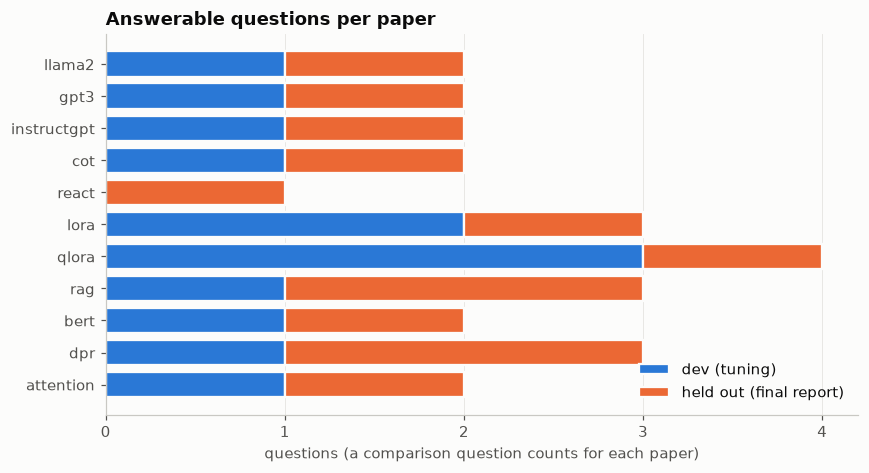

In [13]:
import json

eval_set = json.loads(CONFIG.paths.eval_questions.read_text(encoding="utf-8"))
eval_df = pd.DataFrame(eval_set)
print(eval_df.groupby(["split", "answerable"]).size().rename("questions").to_string(), "\n")
print(eval_df[eval_df["answerable"]].groupby(["type", "split"]).size().unstack(fill_value=0).to_string())

coverage = (eval_df[eval_df["answerable"]].explode("gold_papers")
            .groupby(["gold_papers", "split"]).size().unstack(fill_value=0)
            .reindex(per_paper.index, fill_value=0))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(coverage.index, coverage["dev"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="dev (tuning)")
ax.barh(coverage.index, coverage["held_out"], left=coverage["dev"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="held out (final report)")
ax.grid(axis="y", visible=False)
ax.set_title("Answerable questions per paper")
ax.set_xlabel("questions (a comparison question counts for each paper)")
ax.set_xticks(range(0, int(coverage.sum(axis=1).max()) + 1))
ax.legend(loc="lower right")
fig.tight_layout()

### 3.2 Chunking grid

The grid from the technical plan, plus two capped semantic variants: the semantic chunker has no size limit, so those re-split any chunk longer than 1,200 characters. Sizes are characters for `recursive` and tokens (cl100k) for `fixed`.

In [14]:
from rpab.chunking import ChunkSpec
from rpab.embeddings import load_embedder
from rpab.evaluation import load_eval_set, read_experiments
from rpab.experiments import CHUNK_GRID, run_chunking_grid
from rpab.vectorstore import get_client

dev = load_eval_set(CONFIG.paths.eval_questions, split="dev")
client = get_client(CONFIG.paths.chroma_dir)
bge = load_embedder("open", CONFIG)
NOREF = [ChunkSpec("recursive", 1200, 150, drop_references=True), ChunkSpec("fixed", 512, 0, drop_references=True)]
chunk_results_path = CONFIG.paths.artifacts_dir / "chunking_per_question.parquet"

if RUN_EXPERIMENTS or not chunk_results_path.exists():
    chunk_results = run_chunking_grid(CHUNK_GRID + NOREF, page_table, bge, client, dev, CONFIG)
    chunk_results.to_parquet(chunk_results_path, index=False)
else:
    chunk_results = pd.read_parquet(chunk_results_path)

grid = read_experiments(CONFIG.paths.experiments, "chunking").set_index("chunking")
grid_cols = ["run_id", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "num_chunks",
             "mean_chunk_chars", "embed_seconds", "index_size_mb", "notes"]
grid.loc[~grid.index.str.endswith("_noref"), grid_cols].sort_values(["hit_at_3", "mrr"], ascending=False)

C:\Users\Asus\Desktop\Research Paper Answer Bot\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1024 01:21:22.544000 9260 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 5/391 [00:02<03:12,  2.01it/s]

Loading weights: 100%|██████████| 391/391 [00:02<00:00, 155.36it/s]

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars,embed_seconds,index_size_mb,notes
chunking,,,,,,,,,,,
fixed_512_50,exp_010,0.917,1.000,1.000,0.958,0.611,943,1505.0,13.7,3.9,chunking took 0.7 s
recursive_1200_150,exp_005,0.917,1.000,1.000,0.944,0.639,1418,1005.5,17.8,5.8,chunking took 0.4 s
recursive_800_200,exp_004,0.833,1.000,1.000,0.917,0.667,2277,705.9,18.4,9.3,chunking took 0.4 s
fixed_512_0,exp_009,0.833,1.000,1.000,0.917,0.556,891,1479.8,15.8,3.6,chunking took 0.8 s
semantic_p90,exp_011,0.833,1.000,1.000,0.917,0.667,1576,827.8,15.4,6.5,chunking took 89.0 s
semantic_p95,exp_012,0.833,1.000,1.000,0.917,0.667,1131,1159.3,20.2,4.6,chunking took 88.8 s
recursive_1200_200,exp_006,0.750,1.000,1.000,0.875,0.639,1456,1017.6,15.7,6.0,chunking took 0.4 s
fixed_256_0,exp_007,0.750,1.000,1.000,0.847,0.528,1562,843.1,12.5,6.4,chunking took 0.3 s
semantic_p95_max1200_150,exp_014,0.917,0.917,0.917,0.929,0.611,1740,785.8,16.9,7.1,chunking took 89.2 s


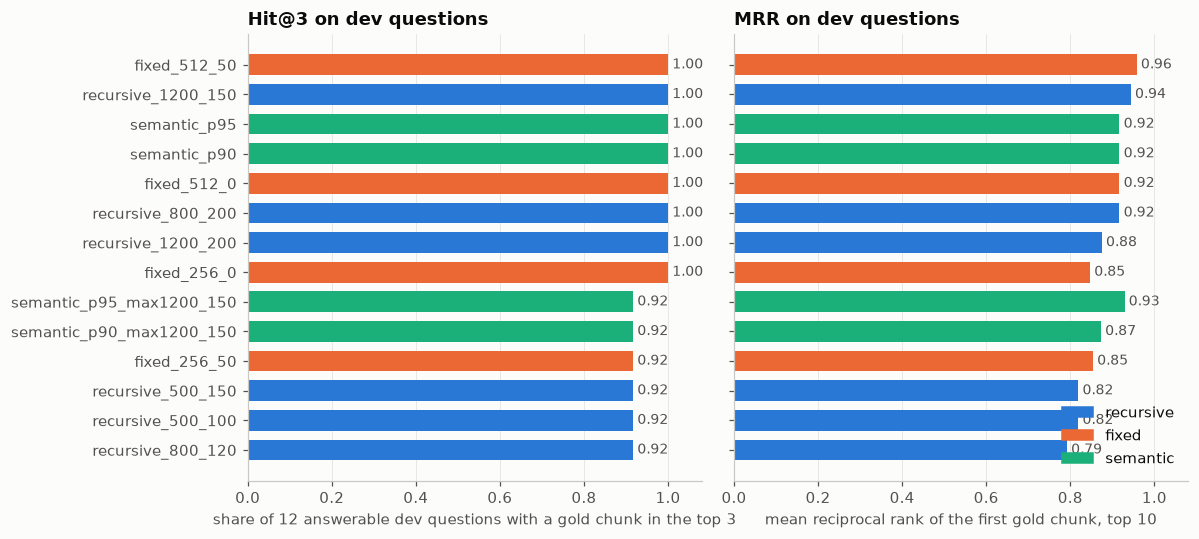

In [15]:
main_grid = grid[~grid.index.str.endswith("_noref")].sort_values(["hit_at_3", "mrr"])
colours = main_grid["chunking_strategy"].map({"recursive": SERIES[0], "fixed": SERIES[1], "semantic": SERIES[2]})
n_dev = sum(q["answerable"] for q in dev)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, col, title in [(ax1, "hit_at_3", "Hit@3 on dev questions"), (ax2, "mrr", "MRR on dev questions")]:
    ax.barh(main_grid.index, main_grid[col], color=colours, height=0.7)
    for y, v in enumerate(main_grid[col]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
ax1.set_xlabel(f"share of {n_dev} answerable dev questions with a gold chunk in the top 3")
ax2.set_xlabel("mean reciprocal rank of the first gold chunk, top 10")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES]
ax2.legend(handles, ["recursive", "fixed", "semantic"], loc="lower right")
fig.tight_layout()

With 12 answerable dev questions, one question moves hit@3 by 0.083. The rank of the first gold chunk per question shows where the configurations really differ (`<NA>` = not in the top 10):

In [16]:
ranks = chunk_results.assign(rank=(1 / chunk_results["reciprocal_rank"]).where(chunk_results["reciprocal_rank"] > 0))
ranks.pivot(index="question_id", columns="chunking", values="rank")[main_grid.index[::-1]].T.astype("Int64")

question_id,q001,q003,q004,q006,q008,q009,q011,q013,q015,q016,q018,q019
chunking,,,,,,,,,,,,
fixed_512_50,1,1,1,1,1,1,1,1,2,1,1,1
recursive_1200_150,1,1,1,1,1,1,3,1,1,1,1,1
semantic_p95,1,1,1,1,1,2,2,1,1,1,1,1
semantic_p90,1,1,1,1,1,2,2,1,1,1,1,1
fixed_512_0,1,1,1,1,1,1,1,1,2,2,1,1
recursive_800_200,1,1,1,1,2,2,1,1,1,1,1,1
recursive_1200_200,1,2,1,1,1,1,2,1,1,2,1,1
fixed_256_0,1,1,1,1,1,3,3,1,1,1,2,1
semantic_p95_max1200_150,1,1,1,1,1,7,1,1,1,1,1,1


recursive_1200_150: 0 chunks over 1,024 tokens, longest 912
fixed_512_0: 0 chunks over 1,024 tokens, longest 513
semantic_p95: 14 chunks over 1,024 tokens, longest 6973


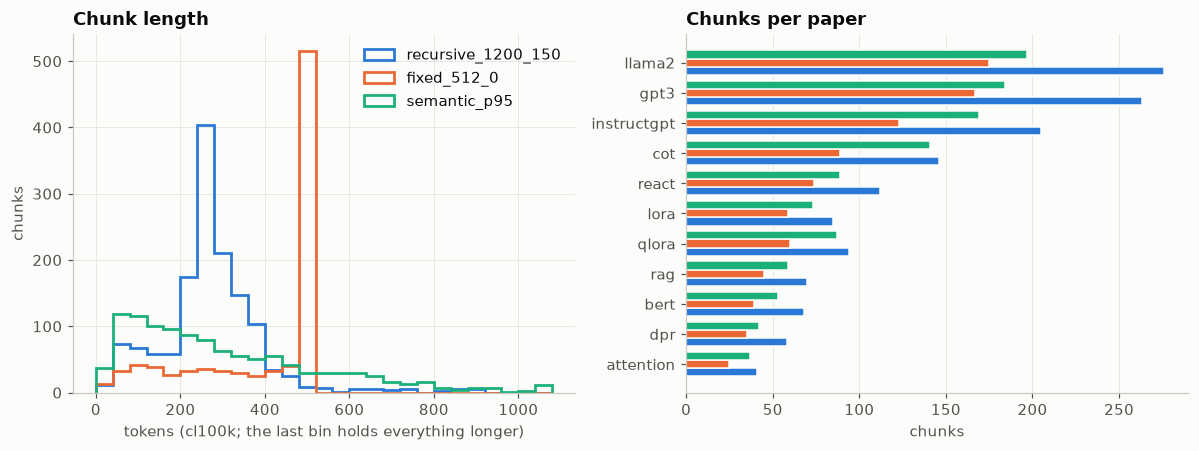

In [17]:
grid_chunks = {slug: pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{slug}.parquet")
               for slug in ["recursive_1200_150", "fixed_512_0", "semantic_p95"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(0, 1100, 40)
for k, (slug, chunks) in enumerate(grid_chunks.items()):
    ax1.hist(chunks["token_count"].clip(upper=1080), bins=bins, histtype="step", linewidth=1.8, color=SERIES[k], label=slug)
ax1.set_title("Chunk length")
ax1.set_xlabel("tokens (cl100k; the last bin holds everything longer)")
ax1.set_ylabel("chunks")
ax1.legend(loc="upper right")

counts = pd.DataFrame({slug: c.groupby("paper_id").size() for slug, c in grid_chunks.items()}).loc[per_paper.index]
rows = range(len(counts))
for k, slug in enumerate(counts.columns):
    ax2.barh([r + (k - 1) * 0.27 for r in rows], counts[slug], height=0.27, color=SERIES[k], edgecolor=SURFACE, linewidth=1)
ax2.set_yticks(list(rows), counts.index)
ax2.grid(axis="y", visible=False)
ax2.set_title("Chunks per paper")
ax2.set_xlabel("chunks")
fig.tight_layout()
for slug, c in grid_chunks.items():
    print(f"{slug}: {(c['token_count'] > 1024).sum()} chunks over 1,024 tokens, longest {c['token_count'].max()}")

### 3.3 Dropping reference lists

Section 2 found that reference lists fill many pages. A chunk is treated as bibliography when it has at least 4 years *and* at least 1 venue word (Proceedings, arXiv, Conference, URL...) per 1,000 characters; heavily cited body text has years but almost never venue words. The two best bounded configurations are re-run without those chunks.

In [18]:
from rpab.chunking import looks_like_references

noref = grid.loc[[s.slug for s in NOREF] + [s.slug.removesuffix("_noref") for s in NOREF], grid_cols[:8]]
display(noref)
full = grid_chunks["fixed_512_0"]
flagged = full[full["text"].map(looks_like_references)]
print(f"fixed_512_0: {len(flagged)} of {len(full)} chunks dropped as bibliography; per paper:",
      flagged.groupby("paper_id").size().to_dict())
print("\nSample dropped chunk:\n" + flagged.sample(1, random_state=CONFIG.seed)["text"].iloc[0][:300])

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars
chunking,,,,,,,,
recursive_1200_150_noref,exp_015,0.917,1.0,1.0,0.944,0.639,1242,1005.8
fixed_512_0_noref,exp_016,0.833,1.0,1.0,0.917,0.528,766,1501.7
recursive_1200_150,exp_005,0.917,1.0,1.0,0.944,0.639,1418,1005.5
fixed_512_0,exp_009,0.833,1.0,1.0,0.917,0.556,891,1479.8


fixed_512_0: 125 of 891 chunks dropped as bibliography; per paper: {'attention': 4, 'bert': 7, 'cot': 12, 'dpr': 5, 'gpt3': 22, 'instructgpt': 14, 'llama2': 19, 'lora': 11, 'qlora': 13, 'rag': 13, 'react': 5}

Sample dropped chunk:
QA: A
question answering challenge targeting commonsense knowledge. NAACL.
Alon Talmor, Oyvind Tafjord, Peter Clark, Yoav Goldberg, and Jonathan Berant. 2020. Leap-ofthought: Teaching pre-trained models to systematically reason over implicit knowledge. NeurIPS.
Alon Talmor, Ori Yoran, Ronan Le Bras,


**Observations** (audited labels).

- Hit@3 no longer separates the configurations: eight of the fourteen reach 1.000 and the rest 0.917, so every configuration finds a gold page in the top 3 for at least 11 of the 12 dev questions. MRR and hit@1 now carry the differences: `fixed_512_50` (MRR 0.958, hit@1 0.917) and `recursive_1200_150` (0.944, 0.917) lead, and `fixed_512_0` follows at 0.917 / 0.833.
- Larger chunks do slightly better: the five configurations averaging 1,000+ characters average MRR 0.922 and hit@1 0.850, against 0.863 and 0.787 for the nine smaller ones. Part of this is the metric itself: gold labels are pages, so a chunk covering more of a page is more likely to count as a hit.
- The clearest failure is q009 (how LoRA initialises A and B): the 500-character and `recursive_800_120` chunkings miss it entirely in the top 10, probably because the sentence about initialisation lands in a small chunk without enough surrounding LoRA context to match the question.
- Overlap has no consistent effect: `fixed_512_50` beats `fixed_512_0` by one rank on one question (q016), while `recursive_1200_200` trails `recursive_1200_150`.
- The semantic chunker is among the best on hit@3 but leaves 14 chunks over 1,024 tokens (the longest, 6,973 tokens, is a table page with no breakpoint). bge-m3 truncates those at its 1,024-token cap. It also takes about 89 s per run because it embeds every sentence. Capping its chunks at 1,200 characters lowers hit@3 to 0.917, so its advantage came from large chunks, not from where it breaks.
- Dropping bibliography chunks removes 125 of 891 chunks (14%) from `fixed_512_0` and 176 from `recursive_1200_150`, and changes no metric. The sample confirms the filter catches reference entries.
- Embedding each grid point with bge-m3 takes 12–21 s on the RTX 4060; vector storage ranges from 3.6 MB (fixed 512) to 15.7 MB (recursive 500).

**Decision.** Keep **`fixed_512_0_noref`**: 512-token chunks, no overlap, bibliography chunks dropped (`CONFIG.chunking_strategy = "fixed"`, `chunk_size = 512`, `chunk_overlap = 0`, `drop_references = True`). It was chosen on the original labels for its tied-best hit@3 and bounded size, and it is still tied for the best hit@3 after the audit. On MRR it now trails `fixed_512_50` and `recursive_1200_150` by about one question ranked second instead of first. Section 6 shows that reranking puts a gold page first for every dev question on this chunking, so the gap does not justify rebuilding every index. Its chunks never exceed 513 tokens, so nothing is truncated and three passages (about 1,200 tokens) fit easily in the 8k context. Known risk: a fixed token window can cut a sentence in two; `fixed_512_50` is the alternative if the failure analysis in section 8 finds answers split across chunks.

## 4. Embedding model comparison

**Intent.** Compare one open-source and one commercial embedding model on the chosen chunking, with the same chunks and the same dev questions, and pick the one the bot uses.

| | `BAAI/bge-m3` | `gemini-embedding-001` |
|---|---|---|
| Type | open-source, runs locally on the GPU (float16) | commercial API, free tier |
| Dimensions | 1,024 | 3,072 |
| Query vs document | same encoder, no prefix | task types `RETRIEVAL_QUERY` / `RETRIEVAL_DOCUMENT` |

Gemini requests carry 50 texts, are paced to stay under the per-minute token limit and retry with backoff on rate-limit errors. Every document vector is cached by text hash, so nothing is embedded twice. The local model is timed by re-embedding from scratch; Gemini's time is its first (uncached) run.

In [19]:
from rpab.embeddings import GeminiEmbedder, GeminiQuotaExhausted
from rpab.experiments import run_embedding_comparison

chunks = pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{CONFIG.chunk_spec.slug}.parquet")
emb_results_path = CONFIG.paths.artifacts_dir / "embedding_per_question.parquet"
# The notebook runs without a Gemini key: saved results are used and live Gemini cells are skipped
gemini = load_embedder("commercial", CONFIG) if CONFIG.google_api_key else None
embedders = {"bge-m3": bge, **({"gemini": gemini} if gemini else {})}

if RUN_EXPERIMENTS or not emb_results_path.exists():
    emb_results = run_embedding_comparison(CONFIG.chunk_spec, chunks, list(embedders.values()), client, dev, CONFIG)
    emb_results.to_parquet(emb_results_path, index=False)
else:
    emb_results = pd.read_parquet(emb_results_path)

emb_table = read_experiments(CONFIG.paths.experiments, "embedding").set_index("embedding_model")
emb_table["dim"] = [bge.dim if "bge" in m else GeminiEmbedder.dim for m in emb_table.index]
emb_table[["run_id", "chunking", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "latency_ms",
           "embed_seconds", "dim", "index_size_mb", "cost_usd"]]

,run_id,chunking,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,latency_ms,embed_seconds,dim,index_size_mb,cost_usd
embedding_model,,,,,,,,,,,,
BAAI/bge-m3,exp_017,fixed_512_0_noref,0.833,1.0,1.0,0.917,0.556,27.4,10.9,1024,3.1,0.0000
models/gemini-embedding-001,exp_018,fixed_512_0_noref,0.833,1.0,1.0,0.889,0.639,474.0,882.1,3072,9.4,0.0457


In [20]:
emb_ranks = emb_results.assign(rank=(1 / emb_results["reciprocal_rank"]).where(emb_results["reciprocal_rank"] > 0))
emb_ranks.pivot(index="question_id", columns="embedding_model", values="rank").astype("Int64")

embedding_model,BAAI/bge-m3,models/gemini-embedding-001
question_id,,
q001,1,1
q003,1,1
q004,1,1
q006,1,1
q008,1,1
q009,1,1
q011,1,3
q013,1,1
q015,2,3


### 4.1 Manual sanity queries

Five questions that are **not** in the eval set, answered by both collections. The top 3 chunks are read by hand to judge whether they are on topic, and whether `paper_title` and `page` came through intact.

In [21]:
from rpab.vectorstore import collection_name, dense_search

SANITY = [
    "What optimizer and learning rate schedule were used to train the Transformer?",
    "Which corpora was BERT pre-trained on?",
    "Which weight matrices of the Transformer does LoRA adapt in its experiments?",
    "What is a paged optimizer?",
    "How does ReAct compare with chain-of-thought prompting on HotpotQA?",
]
sanity_path = CONFIG.paths.artifacts_dir / "sanity_queries.parquet"
saved = pd.read_parquet(sanity_path) if sanity_path.exists() else pd.DataFrame()
rows = []
for name, embedder in embedders.items():
    if not RUN_EXPERIMENTS and not saved.empty and name in set(saved["model"]):
        continue  # reuse the saved results for this model
    collection = client.get_collection(collection_name(embedder.slug, CONFIG.chunk_spec.slug))
    try:
        for q_num, question in enumerate(SANITY, start=1):
            for rank, hit in enumerate(dense_search(collection, embedder, question, 3), start=1):
                rows.append({"query": q_num, "model": name, "rank": rank, "paper_title": hit["paper_title"][:38],
                             "page": hit["page"], "score": hit["score"], "snippet": hit["text"][:110].replace("\n", " ")})
    except GeminiQuotaExhausted as exc:
        rows = [r for r in rows if r["model"] != name]
        print(f"{name} skipped: {exc}")
fresh = pd.DataFrame(rows)
sanity = pd.concat([saved[~saved["model"].isin(set(fresh.get("model", [])))] if not saved.empty else saved, fresh])
if not fresh.empty:
    sanity.to_parquet(sanity_path, index=False)
for q_num, question in enumerate(SANITY, start=1):
    print(f"Q{q_num}. {question}")
sanity.sort_values(["query", "model", "rank"]).set_index(["query", "model", "rank"])

gemini skipped: Gemini's daily free-tier embedding quota is used up; it resets at midnight Pacific time. Use the local model meanwhile (RPAB_EMBEDDING=open).
Q1. What optimizer and learning rate schedule were used to train the Transformer?
Q2. Which corpora was BERT pre-trained on?
Q3. Which weight matrices of the Transformer does LoRA adapt in its experiments?
Q4. What is a paged optimizer?
Q5. How does ReAct compare with chain-of-thought prompting on HotpotQA?


paper_title  page   score  \
query model  rank                                                         
1     bge-m3 1                  Attention Is All You Need     8  0.6124   
             2                  Attention Is All You Need     7  0.6087   
             3     LoRA: Low-Rank Adaptation of Large Lan     9  0.5853   
2     bge-m3 1     BERT: Pre-training of Deep Bidirection     3  0.5630   
             2     BERT: Pre-training of Deep Bidirection     1  0.5302   
             3     BERT: Pre-training of Deep Bidirection     5  0.5117   
3     bge-m3 1     LoRA: Low-Rank Adaptation of Large Lan     5  0.7000   
             2     LoRA: Low-Rank Adaptation of Large Lan     4  0.6318   
             3     LoRA: Low-Rank Adaptation of Large Lan     1  0.6314   
4     bge-m3 1     QLoRA: Efficient Finetuning of Quantiz     5  0.4901   
             2     LoRA: Low-Rank Adaptation of Large Lan     9  0.4786   
             3     Retrieval-Augmented Generation for Kno     4  0.4736   
5     bge-m3 1     ReAct: Synergizing Reasoning and Actin     3  0.7171   
             2     ReAct: Synergizing Reasoning and Actin     2  0.7098   
             3     ReAct: Synergizing Reasoning and Actin     5  0.7005   

                                                                                                     snippet  
query model  rank                                                                                             
1     bge-m3 1     , establishing a new state-of-the-art BLEU score of 28.4. The configuration of this mo...  
             2     machine with 8 NVIDIA P100 GPUs. For our base models using the hyperparameters describ...  
             3     tasks. Note that the low-rank structure not only lowers the hardware barrier to entry ...  
2     bge-m3 1     BERT BERT E[CLS] E1 E[SEP]... EN E1’ ... EM’ C T1 T[SEP]... TN T1’ ... TM’ [CLS] Tok 1...  
             2     BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding Jacob...  
             3     [CLS] he likes play ##ing [SEP]my dog is cute [SEP]Input E[CLS] Ehe Elikes Eplay E##in...  
3     bge-m3 1     guarantees that we do not introduce any additional latency during inference compared t...  
             2     Batch Size 32 16 1 Sequence Length 512 256 128 |Θ| 0.5M 11M 11M Fine-Tune/LoRA 1449.4±...  
             3     LORA: L OW-R ANK ADAPTATION OF LARGE LANGUAGE MODELS Edward Hu∗ Yelong Shen∗ Phillip W...  
4     bge-m3 1     use this feature to allocate paged memory for the optimizer states which are then auto...  
             2     guage models trained on a large amount of text – where fine-tuning on task-specific da...  
             3     minimize the negative marginal log-likelihood of each target,∑j− logp(yj|xj) using sto...  
5     bge-m3 1     We conduct empirical evaluations ofReAct and state-of-the-art baselines on four divers...  
             2     a) Standard, (b) Chain-of-thought ( CoT, Reason Only), (c) Act-only, and (d) ReAct (Re...  
             3     and adopting the majority answer, which is found to consistently boost performance ove...

**Observations** (audited labels).

- Both models put a gold page in the top 3 for all 12 dev questions, and both reach hit@1 0.833. bge-m3 has the higher MRR (0.917 vs 0.889); Gemini the higher precision@3 (0.639 vs 0.556).
- Per question, the two differ on q011 (bge-m3 rank 1, Gemini 3), q015 (2 vs 3) and q016 (2 vs 1).
- Before the audit Gemini looked clearly better (hit@3 1.000 vs 0.917, MRR 0.833 vs 0.736). Most of that gap came from pages the original labels did not list: bge-m3 found correct appendix pages that were scored as misses.
- Sanity queries (not part of the audit): both models put the page that answers the question in the top 3 for all five. Gemini ranks it first in all five; bge-m3 in two (Q3, Q4). bge-m3's misses pull in off-topic chunks (a LoRA page for the Transformer optimizer, a RAG page for paged optimizers). Titles and pages came through intact in every result.
- Cost and speed: bge-m3 embeds the 766 chunks in 11 s locally, for free. Gemini took 882 s, almost all of it waiting, because requests are paced to the free tier's per-minute token limit. About 288k tokens were sent: free on the free tier, about $0.05 at the paid list price. A Gemini query takes 0.5–1 s (a network round trip) against tens of milliseconds locally. Its 3,072-dim vectors take 3× the space (9.4 vs 3.1 MB).
- Gemini adds dependencies: an internet connection, an API key, a daily quota, and query text sent to Google.

**Decision.** First decision (original labels): Gemini, with bge-m3 as the offline fallback. **Revised after the audit: `BAAI/bge-m3`** (`CONFIG.embedding_choice = "open"`). On dense retrieval the two models are now level, and section 6 shows that after reranking they return the same top passages for every dev question. That leaves latency (about 0.55 s vs 0.9–1.3 s per question with reranking, depending on the network), privacy and the API dependency, and all three favour the local model. Gemini stays indexed and selectable (`RPAB_EMBEDDING=commercial`), and section 6.5 reports it on the held-out questions alongside the final system.

## 5. Vector database build

**Intent.** Persist the chosen chunks and their vectors so the bot can start without re-embedding, and prove the index is complete and consistent.

- `artifacts/chunks.parquet` is the canonical chunk table; Chroma and (in section 6) BM25 are rebuilt from it.
- One collection per embedding model × chunking, named `papers__{embedding}__{chunking}`, cosine distance, with the model, dimension, chunking and creation time stored as collection metadata. A query is refused if its embedder differs from the one recorded on the collection.
- `scripts/ingest.py chunk index` rebuilds both from the saved pages.

In [22]:
from rpab.vectorstore import build_collection, time_cold_reload, validate_collection

chunks.to_parquet(CONFIG.paths.chunks, index=False)
collections = {name: build_collection(client, embedder, chunks, CONFIG.chunk_spec.slug)
               for name, embedder in embedders.items()}
for collection in collections.values():
    validate_collection(collection, chunks)  # count = rows, citation fields present, ids unique
    print(f"checks passed: {collection.name} ({collection.count()} vectors)")

pd.DataFrame([{"collection": c.name, **c.metadata} for c in collections.values()]).set_index("collection").T

checks passed: papers__bge_m3__fixed_512_0_noref (766 vectors)
checks passed: papers__gemini_embedding_001__fixed_512_0_noref (766 vectors)


collection,papers__bge_m3__fixed_512_0_noref,papers__gemini_embedding_001__fixed_512_0_noref
embedding_dim,1024,3072
chunk_size,512,512
chunk_overlap,0,0
created_at,2026-10-23T17:16:21+00:00,2026-10-23T17:31:05+00:00
embedding_model,BAAI/bge-m3,models/gemini-embedding-001
chunking,fixed_512_0_noref,fixed_512_0_noref
chunking_strategy,fixed,fixed
hnsw:space,cosine,cosine
num_chunks,766,766


In [23]:
all_collections = sorted(c.name for c in client.list_collections())
print(f"{len(all_collections)} collections on disk, kept for comparison until the final choice is documented")

# Each row is a fresh Python process: open the index, load the query embedder, answer one query
kinds = {"bge-m3": "open", "gemini": "commercial"}
reload_rows = []
for name, c in collections.items():
    try:
        reload_rows.append(time_cold_reload(c.name, kinds[name], SANITY[0]))
    except Exception as exc:  # e.g. Gemini's daily quota; the subprocess reports it on stderr
        print(f"{c.name}: cold reload skipped ({type(exc).__name__})")
pd.DataFrame(reload_rows).set_index("collection")

17 collections on disk, kept for comparison until the final choice is documented


papers__gemini_embedding_001__fixed_512_0_noref: cold reload skipped (CalledProcessError)


,vectors,open_index_s,load_embedder_s,first_query_s,total_s
collection,,,,,
papers__bge_m3__fixed_512_0_noref,766,2.5,18.0,0.7,21.2


In [24]:
# The paper filter behind the UI: a Chroma `where` clause on chunk metadata
filtered = dense_search(collections["bge-m3"], bge, "How much memory does finetuning save?", 3,
                        where={"paper_id": {"$in": ["lora", "qlora"]}})
pd.DataFrame(filtered)[["chunk_id", "paper_title", "page", "score"]]

,chunk_id,paper_title,page,score
0,qlora_p004_c000,QLoRA: Efficient Finetuning of Quantized LLMs,4,0.6028
1,qlora_p001_c001,QLoRA: Efficient Finetuning of Quantized LLMs,1,0.5992
2,lora_p001_c001,LoRA: Low-Rank Adaptation of Large Language Models,1,0.5938


**Observations.**

- Both collections pass the integrity checks: 766 vectors equal the 766 rows of `chunks.parquet`, every record has `paper_title` and `page`, and every `chunk_id` is unique. Each collection's metadata records its model, dimension, chunking and creation time.
- Cold start from a new process: the index itself opens in about 2–3 s. With Gemini the first answer is ready in about 5–6 s. With bge-m3 it takes 14 s when the weights are already in the operating system's file cache, and 29 s from a cold disk (seen on the first run); nearly all of it is loading PyTorch and 2.3 GB of weights. Both are under the 30 s target, the cold case only just, so the apps will load the model once at startup.
- The Chroma `where` filter limits a search to chosen papers (here LoRA and QLoRA) without touching the index. The UI's paper filter will use it.
- 17 collections are on disk: the 16 bge-m3 chunking experiments and the Gemini one.
- Rebuilding a collection can shift close neighbours slightly, because Chroma's HNSW search is approximate. `fixed_512_0_noref` with bge-m3 scored precision@3 0.528 in the chunking run (exp_016) and 0.556 after the rebuild in the embedding run (exp_017), with identical hit@k and MRR. All comparisons in section 6 therefore use one fixed build of each collection.

**Decision.** `artifacts/chunks.parquet` (766 chunks, `fixed_512_0_noref`) is the canonical chunk table. `papers__bge_m3__fixed_512_0_noref` is the default collection, and `papers__gemini_embedding_001__fixed_512_0_noref` is kept as the selectable alternative. `scripts/ingest.py chunk index` rebuilds both. The experiment collections stay until the final choice is written up, then get deleted (doc 05, section 11).

## 6. Retrieval strategy comparison

**Intent.** Choose how the bot finds its three passages, testing retrieval on its own before any LLM is connected. Six strategies run over the chosen chunking (`fixed_512_0_noref`), each with both embedding models:

| Strategy | How it works | Parameters tried |
|---|---|---|
| `dense` | cosine similarity in Chroma | — |
| `mmr` | maximal marginal relevance over 20 dense candidates | λ = 0.5, 0.7 |
| `bm25` | keyword search (`rank_bm25`, tokenizer v1: lowercase, alphanumeric, stop words removed) | — |
| `hybrid` | BM25 and dense lists merged by weighted reciprocal rank fusion (k = 60) | dense weight 0.3, 0.5, 0.7 |
| `hybrid_rerank` | hybrid's top 20 rescored by `BAAI/bge-reranker-v2-m3` | — |
| `multi_query` | llama3.1 writes 3 rephrasings; hybrid per query, fused, reranked | — |

Every strategy honours the paper filter (a Chroma `where` clause for dense search, a post-filter for BM25) and deduplicates by `chunk_id` before reranking.

**Method.** Dev questions only; each strategy returns its top 10. Latency is measured in two passes: an untimed pass warms the GPU and embeds every query once, then the timed pass is charged the time each real query embedding and LLM rephrasing took. So it excludes one-time warm-up and free-tier pacing waits, but includes everything one user question costs. All runs use one fixed build of each collection.

### 6.1 Gold-page audit

The first sweep (on the original labels) suggested the reranker made things *worse*: with Gemini, plain dense search had hit@3 1.000 and hybrid + rerank 0.917. Reading the reranker's top picks showed why: several were correct pages the labels did not list, because the papers repeat key facts in their appendices. For example:

- q003 (BERT masking): the reranker's first pick was page 12, the appendix that spells out "80% of the time: Replace the word with the [MASK] token… 10%… 10%". Only page 4 was gold.
- q018 (Llama 2 tokens and context): page 47, "We expand the context window for Llama 2 from 2048 tokens to 4096 tokens". Only pages 5–6 were gold.
- q019 (LoRA vs QLoRA): QLoRA page 3, "QLoRA improves over LoRA by quantizing the transformer model to 4-bit precision". Not gold.

So the labels were audited for every answerable question, dev and held-out alike, with a method that cannot favour any strategy. Candidate pages came from **searching the page text for each question's key facts**, never from retrieval output; each candidate was read and kept only if it met the gold rule in section 3.1. 13 of the 24 answerable questions gained pages and none lost any; 11 were unchanged:

| Question | Added pages | Example of what the added page states |
|---|---|---|
| q003 BERT masking | 12, 13, 16 | p13: "a uniform masking rate of 15%" |
| q004 DPR in-batch negatives | 6 | the in-batch training scheme, gold negatives from the same batch |
| q007 RAG components (held-out) | 4, 5 | p5: "RAG's retriever is initialized using DPR's retriever" |
| q010 LoRA savings (held-out) | 5, 9 | p5: VRAM 1.2 TB → 350 GB; p9: "up to 10,000×" fewer trainable parameters |
| q012 CoT scale (held-out) | 5, 21, 22 | "an emergent ability of model scale" (figure and table captions) |
| q013 InstructGPT steps | 7, 8, 9 | p8: "we then train models with three different techniques" |
| q015 NF4 | 1, 2 | "information theoretically optimal for normally distributed weights" |
| q016 Double Quantization | 1 | "quantizing the quantization constants" |
| q017 GAtt (held-out) | 8 | "helps control dialogue flow over multiple turns" |
| q018 Llama 2 tokens/context | 4, 47, 77 | p47: 2048 → 4096 tokens; p77: "pretrained on 2 trillion tokens" |
| q019 LoRA vs QLoRA | LoRA 2; QLoRA 1, 2, 3, 5 | QLoRA p1: "a frozen, 4-bit quantized pretrained language model" |
| q020 RAG and DPR (held-out) | RAG 4, 5 | p4: "a single MIPS index" |
| q031 Guanaco memory (held-out) | 9, 10, 26 | p9: "Guanaco 7B … at a 5 GB footprint" |

Every logged run (sections 3–6) was then re-scored from its saved retrieval results, which is exact because a chunk id encodes its paper and page. The audit reversed one earlier decision, the embedding model (section 4).

In [25]:
from rpab.experiments import calibrate_threshold, confidence_table, run_held_out, run_strategy_sweep
from rpab.retrievers import BM25Index, MultiQuery, Reranker, Retriever

bm25 = BM25Index.load_or_build(CONFIG.paths.bm25, chunks)  # saved in artifacts/bm25.joblib
reranker = Reranker(CONFIG.reranker_model) if CONFIG.use_reranker else None
by_kind = {"open": bge, "commercial": gemini}


def retriever_for(kind, cfg):
    embedder = by_kind[kind]
    collection = client.get_collection(collection_name(embedder.slug, cfg.chunk_spec.slug))
    return Retriever(cfg, embedder, collection, chunks, bm25, reranker, MultiQuery(cfg, cfg.paths.multi_query_cache))


eval_df[eval_df["answerable"]][["id", "split", "type", "gold_pages"]].set_index("id")

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-reranker-v2-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-reranker-v2-m3'.


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   9%|▉         | 35/393 [00:00<00:01, 341.66it/s]

Loading weights:  18%|█▊        | 70/393 [00:00<00:01, 249.35it/s]

Loading weights:  25%|██▍       | 97/393 [00:00<00:01, 235.00it/s]

...

Loading weights:  86%|████████▌ | 338/393 [00:01<00:00, 156.72it/s]

Loading weights:  90%|█████████ | 354/393 [00:01<00:00, 141.78it/s]

Loading weights:  95%|█████████▍| 373/393 [00:02<00:00, 148.69it/s]

Loading weights: 100%|██████████| 393/393 [00:02<00:00, 181.85it/s]

,split,type,gold_pages
id,,,
q001,dev,conceptual,{'attention': [4]}
q002,held_out,numeric,{'attention': [5]}
q003,dev,method_detail,"{'bert': [4, 12, 13, 16]}"
q004,dev,method_detail,"{'dpr': [3, 4, 6]}"
q005,held_out,numeric,{'dpr': [5]}
q006,dev,conceptual,"{'rag': [2, 3]}"
q007,held_out,factual,"{'rag': [2, 3, 4, 5]}"
q008,dev,numeric,{'gpt3': [8]}
q009,dev,method_detail,{'lora': [4]}


### 6.2 Strategy comparison (dev)

In [26]:
sweep_path = CONFIG.paths.artifacts_dir / "retrieval_per_question.parquet"
if RUN_EXPERIMENTS or not sweep_path.exists():
    sweep = run_strategy_sweep(retriever_for, ["open", "commercial"], dev, CONFIG)
    sweep.to_parquet(sweep_path, index=False)
else:
    sweep = pd.read_parquet(sweep_path)

runs = read_experiments(CONFIG.paths.experiments, "retrieval")
runs["model"] = runs["embedding_model"].map(lambda m: "bge-m3" if "bge" in m else "gemini")
dev_runs = runs[runs["split"] == "dev"]
order = ["bm25", "dense", "mmr_l0.5", "mmr_l0.7", "hybrid_w0.3", "hybrid_w0.5", "hybrid_w0.7", "hybrid_rerank", "multi_query"]
strategy_table = (dev_runs.pivot_table(index="retrieval_strategy", columns="model",
                                       values=["hit_at_1", "hit_at_3", "mrr", "precision_at_3", "latency_ms"])
                  .reindex(order))
strategy_table.round(3)

hit_at_1        hit_at_3        latency_ms            mrr        precision_at_3       
model                bge-m3 gemini   bge-m3 gemini     bge-m3  gemini bge-m3 gemini         bge-m3 gemini
retrieval_strategy                                                                                       
bm25                  0.500    NaN    0.833    NaN        5.6     NaN  0.677    NaN          0.417    NaN
dense                 0.833  0.833    1.000  1.000      170.1   500.7  0.917  0.889          0.556  0.639
mmr_l0.5              0.833  0.833    1.000  0.917      171.8   511.3  0.903  0.884          0.472  0.444
mmr_l0.7              0.833  0.833    1.000  0.917      172.5   504.3  0.917  0.885          0.583  0.583
hybrid_w0.3           0.583  0.833    0.917  0.917      177.7   511.6  0.753  0.896          0.556  0.528
hybrid_w0.5           0.750  0.917    1.000  1.000      179.0   514.7  0.875  0.958          0.556  0.611
hybrid_w0.7           0.917  0.833    1.000  1.000      178.4   512.8  0.958  0.917          0.556  0.639
hybrid_rerank         1.000  1.000    1.000  1.000      552.4   900.1  1.000  1.000          0.611  0.611
multi_query           1.000  1.000    1.000  1.000     4928.8  7641.7  1.000  1.000          0.556  0.611

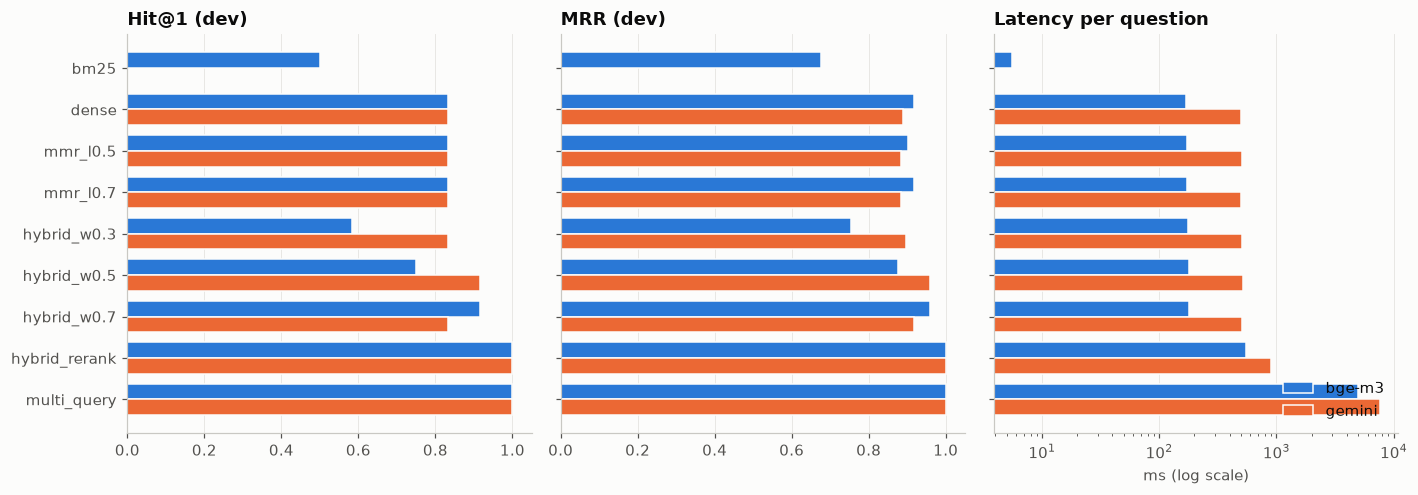

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
rows = range(len(order))
for k, model in enumerate(["bge-m3", "gemini"]):
    data = dev_runs[dev_runs["model"] == model].set_index("retrieval_strategy").reindex(order)
    offset = (k - 0.5) * 0.38
    for ax, col in [(ax1, "hit_at_1"), (ax2, "mrr"), (ax3, "latency_ms")]:
        ax.barh([r + offset for r in rows], data[col], height=0.38, color=SERIES[k], edgecolor=SURFACE,
                linewidth=1, label=model)
ax1.set_yticks(list(rows), order)
ax1.invert_yaxis()
ax1.set_title("Hit@1 (dev)")
ax2.set_title("MRR (dev)")
ax3.set_title("Latency per question")
ax3.set_xscale("log")
ax3.set_xlabel("ms (log scale)")
for ax in (ax1, ax2):
    ax.set_xlim(0, 1.05)
for ax in (ax1, ax2, ax3):
    ax.grid(axis="y", visible=False)
ax3.legend(loc="lower right")
fig.tight_layout()

Rank of the first gold chunk per dev question (`<NA>` = not in the top 10):

In [28]:
sweep["rank"] = (1 / sweep["reciprocal_rank"]).where(sweep["reciprocal_rank"] > 0)
sweep["model"] = sweep["embedding_model"].map(lambda m: "bge-m3" if "bge" in m else "gemini")
(sweep.pivot_table(index=["model", "strategy"], columns="question_id", values="rank")
 .reindex(order, level=1).astype("Int64"))

question_id           q001  q003  q004  q006  q008  q009  q011  q013  q015  q016  q018  q019
model  strategy                                                                             
bge-m3 bm25              1     1     1     1     7     2     7     1     1     2     3     2
       dense             1     1     1     1     1     1     1     1     2     2     1     1
       mmr_l0.5          1     1     1     1     1     1     1     1     2     3     1     1
       mmr_l0.7          1     1     1     1     1     1     1     1     2     2     1     1
       hybrid_w0.3       1     1     1     1     3     2     5     1     1     2     1     2
       hybrid_w0.5       1     1     1     1     2     1     2     1     1     2     1     1
       hybrid_w0.7       1     1     1     1     1     1     1     1     1     2     1     1
       hybrid_rerank     1     1     1     1     1     1     1     1     1     1     1     1
       multi_query       1     1     1     1     1     1     1     1     1     1     1     1
gemini dense             1     1     1     1     1     1     3     1     3     1     1     1
       mmr_l0.5          1     1     1     1     1     1     9     1     2     1     1     1
       mmr_l0.7          1     1     1     1     1     1     8     1     2     1     1     1
       hybrid_w0.3       1     1     1     1     1     1     4     1     1     2     1     1
       hybrid_w0.5       1     1     1     1     1     1     2     1     1     1     1     1
       hybrid_w0.7       1     1     1     1     1     1     2     1     2     1     1     1
       hybrid_rerank     1     1     1     1     1     1     1     1     1     1     1     1
       multi_query       1     1     1     1     1     1     1     1     1     1     1     1

### 6.3 Weak-context threshold

The bot should refuse when the papers do not contain the answer. Before generation, the score of the best passage is compared with a threshold: the reranker's probability when results are reranked, otherwise the best cosine similarity (CPU profile). The threshold is the midpoint between scores that best separates the 12 answerable dev questions from the 3 out-of-scope ones (balanced accuracy, ties to the lower value).

In [29]:
conf_dev_path = CONFIG.paths.artifacts_dir / "confidence_dev.parquet"
if RUN_EXPERIMENTS or not conf_dev_path.exists():
    conf_dev = pd.concat([confidence_table(retriever_for(kind, CONFIG), strategy, dev)
                          .assign(model=by_kind[kind].slug, strategy=strategy)
                          for kind in ("open", "commercial") for strategy in ("hybrid_rerank", "dense")])
    conf_dev.to_parquet(conf_dev_path, index=False)
else:
    conf_dev = pd.read_parquet(conf_dev_path)

calibration = pd.DataFrame([{"model": m, "strategy": s, **calibrate_threshold(t)}
                            for (m, s), t in conf_dev.groupby(["model", "strategy"])]).set_index(["model", "strategy"])
print("Thresholds in CONFIG:", CONFIG.confidence_thresholds)
calibration

Thresholds in CONFIG: {'rerank': 0.7205, 'bge_m3': 0.6091, 'gemini_embedding_001': 0.7525}


threshold  balanced_accuracy  answerable_kept  out_of_scope_flagged
model                strategy                                                                          
bge_m3               dense             0.6091              0.917            0.833                   1.0
                     hybrid_rerank     0.7205              1.000            1.000                   1.0
gemini_embedding_001 dense             0.7525              0.958            0.917                   1.0
                     hybrid_rerank     0.7205              1.000            1.000                   1.0

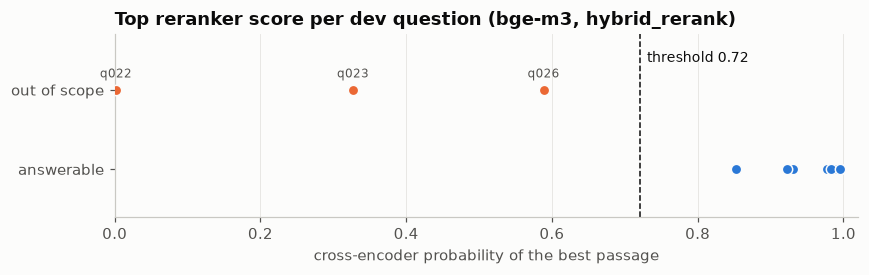

In [30]:
final_dev = conf_dev[(conf_dev["model"] == "bge_m3") & (conf_dev["strategy"] == "hybrid_rerank")]
fig, ax = plt.subplots(figsize=(8, 2.6))
for k, (answerable, label) in enumerate([(True, "answerable"), (False, "out of scope")]):
    part = final_dev[final_dev["answerable"] == answerable]
    ax.scatter(part["score"], [k] * len(part), s=46, color=SERIES[k], edgecolor=SURFACE, linewidth=1, zorder=3)
    for _, r in part.iterrows():
        if not answerable:
            ax.annotate(r["question_id"], (r["score"], k), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8, color=INK_2)
ax.axvline(CONFIG.confidence_thresholds["rerank"], color=INK, linewidth=1, linestyle="--")
ax.text(CONFIG.confidence_thresholds["rerank"] + 0.01, 1.35, f"threshold {CONFIG.confidence_thresholds['rerank']:.2f}",
        fontsize=9, color=INK)
ax.set_yticks([0, 1], ["answerable", "out of scope"])
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(0, 1.02)
ax.grid(axis="y", visible=False)
ax.set_title("Top reranker score per dev question (bge-m3, hybrid_rerank)")
ax.set_xlabel("cross-encoder probability of the best passage")
fig.tight_layout()

### 6.4 Paper filter and a refusal case

The paper filter restricts every strategy to chosen papers. The second query is the out-of-scope trap q027: BERT never reports its energy use, but Llama 2 reports carbon emissions, so the top passage is plausible-looking yet below the threshold.

In [31]:
final = retriever_for(CONFIG.embedding_choice, CONFIG)
strategy = CONFIG.retrieval_strategy if final.reranker else "hybrid"
demo = []
for question, papers in [("How much memory does finetuning save?", ["lora", "qlora"]),
                         ("How much electricity or CO2 did pre-training BERT consume or emit?", None)]:
    results = final.retrieve(question, strategy, paper_ids=papers)
    score, kind = final.confidence(results)
    for rank, c in enumerate(results, start=1):
        demo.append({"question": question[:45], "filter": ",".join(papers or ["all"]), "rank": rank,
                     "chunk_id": c.chunk_id, "paper_title": c.paper_title[:40], "page": c.page,
                     "rerank_score": c.rerank_score, "weak_context": final.is_weak(results)})
pd.DataFrame(demo).set_index(["question", "rank"])

filter          chunk_id                               paper_title  page  rerank_score  weak_context
question                                      rank                                                                                                          
How much memory does finetuning save?         1     lora,qlora   qlora_p001_c000  QLoRA: Efficient Finetuning of Quantized     1      0.856812         False
                                              2     lora,qlora   qlora_p001_c001  QLoRA: Efficient Finetuning of Quantized     1      0.661923         False
                                              3     lora,qlora   qlora_p004_c000  QLoRA: Efficient Finetuning of Quantized     4      0.610628         False
How much electricity or CO2 did pre-training  1            all  llama2_p007_c000  Llama 2: Open Foundation and Fine-Tuned      7      0.512761          True
                                              2            all    bert_p001_c000  BERT: Pre-training of Deep Bidirectional     1      0.198219          True
                                              3            all    bert_p013_c000  BERT: Pre-training of Deep Bidirectional    13      0.188175          True

### 6.5 Held-out results (reported once)

The final configuration was fixed before the held-out questions were scored: **bge-m3 + `hybrid_rerank`**, dense weight 0.5, weak-context threshold 0.72. The other rows give context and were not used for any choice.

In [32]:
held = load_eval_set(CONFIG.paths.eval_questions, split="held_out")
held_path = CONFIG.paths.artifacts_dir / "retrieval_heldout_per_question.parquet"
held_conf_path = CONFIG.paths.artifacts_dir / "confidence_heldout.parquet"
if RUN_EXPERIMENTS or not held_path.exists():
    held_results, held_conf = run_held_out(retriever_for, held, CONFIG)
    held_results.to_parquet(held_path, index=False)
    held_conf.to_parquet(held_conf_path, index=False)
else:
    held_results, held_conf = pd.read_parquet(held_path), pd.read_parquet(held_conf_path)

held_runs = runs[runs["split"] == "held_out"].assign(role=lambda d: d["notes"].str.replace("held-out, reported only: ", ""))
held_runs[["run_id", "role", "model", "retrieval_strategy", "hit_at_1", "hit_at_3", "hit_at_5", "mrr",
           "precision_at_3", "latency_ms"]].set_index("run_id")

,role,model,retrieval_strategy,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,latency_ms
run_id,,,,,,,,,
exp_036,final system,bge-m3,hybrid_rerank,0.750,1.000,1.000,0.847,0.528,563.6
exp_037,baseline,bge-m3,dense,0.667,0.833,0.833,0.736,0.472,161.0
exp_038,CPU profile (no reranker),bge-m3,hybrid,0.750,0.833,0.833,0.801,0.472,172.0
exp_039,alternative embedding,gemini,hybrid_rerank,0.833,1.000,1.000,0.889,0.556,893.5
exp_040,alternative baseline,gemini,dense,0.750,1.000,1.000,0.861,0.667,503.6


In [33]:
check = (held_conf.groupby(["role", "answerable"])["flagged_weak"].agg(flagged="sum", questions="count")
         .rename(index={True: "answerable", False: "out of scope"}, level=1))
print(check.to_string(), "\n")
held_conf[["role", "question_id", "answerable", "score", "flagged_weak", "top_is_gold"]].round(3).set_index(["role", "question_id"])

                                        flagged  questions
role                      answerable                      
CPU profile (no reranker) out of scope        2          2
                          answerable          1         12
final system              out of scope        2          2
                          answerable          0         12 



answerable  score  flagged_weak  top_is_gold
role                      question_id                                              
final system              q002               True  0.979         False         True
                          q005               True  0.997         False         True
                          q007               True  0.906         False         True
                          q010               True  1.000         False         True
                          q012               True  0.994         False        False
                          q014               True  0.980         False         True
                          q017               True  0.926         False         True
                          q020               True  0.766         False        False
                          q025              False  0.019          True        False
                          q027              False  0.513          True        False
                          q028               True  0.934         False         True
                          q029               True  0.984         False        False
                          q030               True  0.997         False         True
                          q031               True  0.997         False         True
CPU profile (no reranker) q002               True  0.664         False         True
                          q005               True  0.714         False         True
                          q007               True  0.574          True         True
                          q010               True  0.680         False         True
                          q012               True  0.753         False        False
                          q014               True  0.695         False         True
                          q017               True  0.647         False         True
                          q020               True  0.631         False        False
                          q025              False  0.503          True        False
                          q027              False  0.564          True        False
                          q028               True  0.710         False         True
                          q029               True  0.699         False        False
                          q030               True  0.720         False         True
                          q031               True  0.665         False         True

**Observations.**

- **Reranking is what matters.** `hybrid_rerank` puts a gold page first for all 12 dev questions with both embedding models (hit@1 and MRR 1.000), against hit@1 0.833 for plain dense search. On the held-out questions it lifts bge-m3 from hit@3 0.833 to 1.000 and MRR from 0.736 to 0.847. On dev it returns the same top passages whichever embedding supplied the candidates.
- **Multi-query adds nothing measurable.** It matches `hybrid_rerank` on dev but costs 4.9 s (bge-m3) to 7.6 s (Gemini) per question for the LLM rephrasings, against 0.55 s and 0.9 s. The dev set is saturated at this point, so if multi-query helps on harder questions this evaluation cannot show it.
- **MMR does not help.** Trading relevance for diversity never raises hit@1 and lowers hit@3 to 0.917 with Gemini. The papers rarely return near-duplicate chunks, so there is little redundancy to remove.
- **BM25 alone is weakest** (hit@1 0.500, MRR 0.677), but it is a useful partner: plain hybrid search beats dense at the right weight (bge-m3 with weight 0.7: MRR 0.958 vs 0.917). The best weight differs by model (0.7 for bge-m3, 0.5 for Gemini) and the spread is about one question, so the neutral 0.5 is kept instead of a value fitted to 12 questions. Under reranking the weight does not matter: the 20 candidates contain a gold page either way.
- **Weak-context threshold.** With reranking, answerable dev questions score at least 0.852 and out-of-scope ones at most 0.589 (q026, GPT-3's training cost, the hardest negative), so the midpoint 0.72 separates them perfectly. On the held-out questions it flags both out-of-scope questions, including the BERT-energy trap at 0.513, and none of the 12 answerable ones, but the margin is smaller: the lowest answerable score is 0.766 (q020). Without the reranker, cosine scores overlap: the CPU profile's threshold (0.609) flags both held-out refusals but also one answerable question (q007, 0.574).
- **Held-out vs dev.** The final system drops from hit@1 1.000 on dev to 0.750 on held-out (q012, q020 and q029 have a gold page at rank 2 or 3 rather than first), while keeping hit@3 at 1.000. Part of the dev result is fitting to 12 questions; the held-out figures are the ones to report.
- **Gemini on held-out** is one question ahead at rank 1 (hit@1 0.833, MRR 0.889 vs 0.750, 0.847). That is reported but does not reverse the choice, which was fixed before the held-out run. The experiments also ran into Gemini's free-tier limit of 1,000 embedding requests per day, which ended the session's Gemini runs for 11 hours; the embedder now stops at once with a clear message instead of retrying.
- Latency of the final configuration is about 0.55 s per question on the RTX 4060 (embedding, BM25, fusion and reranking 20 candidates), well inside the 8 s budget, which leaves room for generation.

**Decision.** Use **`hybrid_rerank` over bge-m3** (`CONFIG.retrieval_strategy = "hybrid_rerank"`, `hybrid_dense_weight = 0.5`, 20 candidates reranked to the top 3, weak-context threshold 0.72 on the reranker score). On held-out questions it reaches hit@3 1.000, hit@1 0.750 and MRR 0.847 in about 0.55 s. Without a GPU the reranker is switched off and the bot falls back to plain hybrid search with the cosine threshold 0.609; that profile is weaker (held-out hit@3 0.833, one answerable question wrongly flagged) and is documented as reduced quality. Multi-query and MMR stay available in the code but are not offered as defaults. The main limitation is the evaluation itself: with 12 dev and 12 held-out answerable questions, the strategies above plain hybrid cannot be separated further.